# Group2

Swostika lama = 2424852
Jiya Jameela Kanhirathan Poyil = 2414377


Puntawat Subhamani = 2412117
Sachin Bhandari = 2324467

# Activity 3: An MLP for Real-World Regression — Cereal Ratings


In [1]:
!pip install numpy pandas matplotlib scikit-learn keras tensorflow

## 1. From classification to regression


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import Sequential, Input
from keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

keras.utils.set_random_seed(32)
print("Keras version:", keras.__version__)
print("Keras backend:", keras.config.backend())

Keras version: 3.13.2
Keras backend: tensorflow


## 2. Load and explore the cereal dataset


In [3]:
cereal_data = pd.read_csv(
    "https://raw.githubusercontent.com/AI-Learning-Repo/resources/refs/heads/main/datasets/cereal.csv"
)

In [4]:
# 1. Display the first five rows
print('First five rows:\n', cereal_data.head())

First five rows:
                         name mfr type  calories  protein  fat  sodium  fiber  \
0                  100% Bran   N    C        70        4    1     130   10.0   
1          100% Natural Bran   Q    C       120        3    5      15    2.0   
2                   All-Bran   K    C        70        4    1     260    9.0   
3  All-Bran with Extra Fiber   K    C        50        4    0     140   14.0   
4             Almond Delight   R    C       110        2    2     200    1.0   

   carbo  sugars  potass  vitamins  shelf  weight  cups     rating  
0    5.0       6     280        25      3     1.0  0.33  68.402973  
1    8.0       8     135         0      3     1.0  1.00  33.983679  
2    7.0       5     320        25      3     1.0  0.33  59.425505  
3    8.0       0     330        25      3     1.0  0.50  93.704912  
4   14.0       8      -1        25      3     1.0  0.75  34.384843  


In [5]:
# 2. Print the number of rows and columns
print('Number of rows and columns:\n', cereal_data.shape)

Number of rows and columns:
 (77, 16)


In [6]:
# 3. Identify target and count the input features we will use
print('Target variable:\n', cereal_data.columns[-1])
# print('Input features:\n', cereal_data.columns[1:])
print('Input features:\n', cereal_data.columns.tolist()[3:-4])
print(len(cereal_data.columns[3:-4]))

Target variable:
 rating
Input features:
 ['calories', 'protein', 'fat', 'sodium', 'fiber', 'carbo', 'sugars', 'potass', 'vitamins']
9


4. Explain why this is **regression**, not classification.

<details>
<summary><strong>Solution </strong></summary>
Because the target variable is continuous numerical value not a category.
</details>

## 3. Separate features and target; inspect missing markers


In [7]:
feature_columns = [
    "calories", "protein", "fat", "sodium", "fiber",
    "carbo", "sugars", "potass", "vitamins"
]

cereal_features = cereal_data[feature_columns].copy()
cereal_target = cereal_data["rating"].copy()

missing_marker_columns = ["carbo", "sugars", "potass"]
cereal_features[missing_marker_columns] = (
    cereal_features[missing_marker_columns].replace(-1, np.nan)
)

print("Features:", cereal_features.shape)
print("Target:", cereal_target.shape)
print("Missing values by feature:")
print(cereal_features.isna().sum())

Features: (77, 9)
Target: (77,)
Missing values by feature:
calories    0
protein     0
fat         0
sodium      0
fiber       0
carbo       1
sugars      1
potass      2
vitamins    0
dtype: int64


**Questions**

1. Why do we exclude `rating` from the features?
2. Why did we convert selected `-1` entries into `np.nan`?
3. Why should we **not** replace every `0` with a missing value?

<details>
<summary><strong>Answer: </strong></summary>

1. Because rating is the target
2. Because -1 here represent missing values, not meaningful negative values
3. Because 0 could be the real value???
</details>

# 4. Split the dataset before fitting preprocessing

In [8]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    cereal_features, cereal_target, test_size=0.20, random_state=32
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.20, random_state=32
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (48, 9)
Validation: (13, 9)
Test: (16, 9)


**Your tasks**

1. Explain why the test set is not used for architecture comparisons.
2. Why does taking 20% of the *remaining* 80% for validation result in approximately a **64% / 16% / 20%** split?

<details><summary><strong>Answers: </strong></summary>

1. Because then test set can no longer be unbiased data because we evaluate the performance of the model on it???
2. Because 20% of 80% is 16%
</details>

# 5. Impute missing values and scale the features

In [9]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_val_scaled = scaler.transform(X_val_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Training input shape:", X_train_scaled.shape)
print("Missing values after imputation:", np.isnan(X_train_scaled).sum())

Training input shape: (48, 9)
Missing values after imputation: 0


**Questions**

1. What does median imputation do?
2. Why use `fit_transform()` on training inputs but only `transform()` on validation and test inputs?
3. What does standardization do, and why might it help neural networks?

<details>
<summary><strong>Answers: </strong></summary>

1. Median imputation imputes missing value with the median of the fitted dataset.
2. Fit the imputer only on training dataset to avoid data leak
3. Make optimization more stable when input features have very different numerical range? idk?

</details>


## 6. Build an MLP for regression


In [10]:
model = Sequential(name="Cereal_MLP")
model.add(Input(shape=(X_train_scaled.shape[1],)))
model.add(Dense(64, activation="relu"))
model.add(Dense(32, activation="relu"))
model.add(Dense(1))  # Default: linear activation for regression

model.summary()

Model: "Cereal_MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,753 (10.75 KB)

 Trainable params: 2,753 (10.75 KB)

 Non-trainable params: 0 (0.00 B)

**Your tasks**

1. Identify input, hidden, and output layers.
2. Why does the final neuron use a **linear** output rather than sigmoid?
3. Calculate the trainable parameters in each Dense layer and the total.

<details>
<summary><strong>Solution / explanation</strong>
</summary>

1. **Input values** : 9 , **hidden layers** = 64 and **output layers** =  640

2. Because it does not restrict predictions to the interval 0-1, unlike sigmoid in XOR.

3. | Dense layer | Calculation | Parameters |
|---|---|---:|
| 9 → 64 | `(9 × 64) + 64` | 640 |
| 64 → 32 | `(64 × 32) + 32` | 2,080 |
| 32 → 1 | `(32 × 1) + 1` | 33 |
| **Total** | | **2,753** |

The formula for a Dense layer is **(inputs × neurons) + biases**, with one bias per neuron.


</details>

##7. Compile and train the baseline

In [11]:
model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

history = model.fit(
    X_train_scaled, y_train,
    epochs=50,
    batch_size=16,
    validation_data=(X_val_scaled, y_val),
    verbose=0
)

print("Final training MAE:", round(history.history["mae"][-1], 2))
print("Final validation MAE:", round(history.history["val_mae"][-1], 2))

Final training MAE: 16.3
Final validation MAE: 13.99


**Questions**

1. What is the difference between **MSE** and **MAE**?

<details>
<summary><strong>Answer</strong></summary>

- **MSE** averages squared errors; its units here are **rating points squared**. Larger errors count especially heavily.
- **MAE** averages absolute errors; its units are **rating points**, so it is easier to interpret.

</details>

2. What do `epochs`, `batch_size`, and `validation_data` control?

<details>
<summary><strong>Answer</strong></summary>

An epoch is one pass through the training set. Batch size controls how many examples are used per training step. Validation data measures performance after each epoch without updating weights from those examples.

</details>

3. Does a lower training error guarantee a lower validation error?

<details>
<summary><strong>Answer</strong></summary>
 **No.** A model can improve on the training examples without improving on unseen examples; this is one reason to monitor validation performance.

We use Keras training tools today; the internal gradient and backpropagation mathematics is covered later.

</details>

##8. Visualize training and validation performance


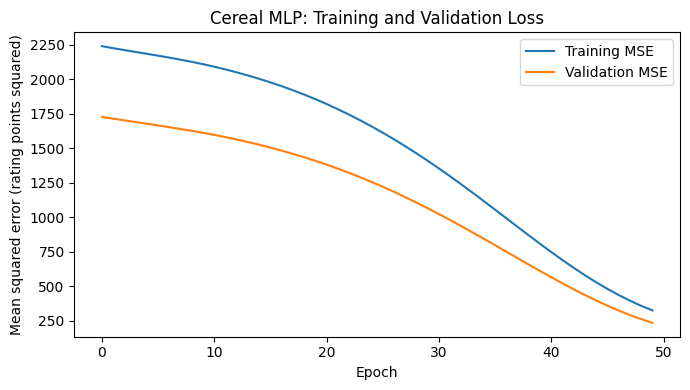

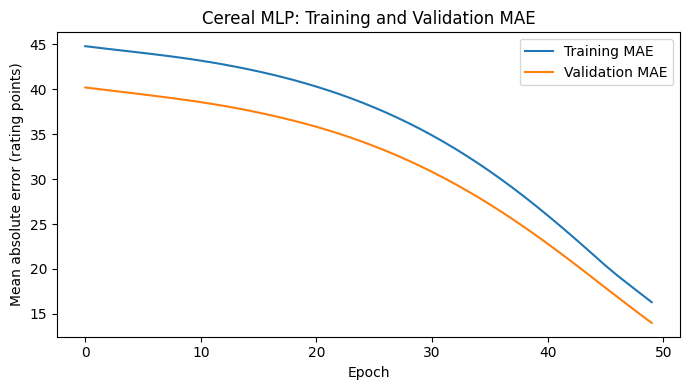

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training MSE")
plt.plot(history.history["val_loss"], label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error (rating points squared)")
plt.title("Cereal MLP: Training and Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["mae"], label="Training MAE")
plt.plot(history.history["val_mae"], label="Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("Mean absolute error (rating points)")
plt.title("Cereal MLP: Training and Validation MAE")
plt.legend()
plt.tight_layout()
plt.show()

**Questions**

1. Does the training loss generally decrease?
<details>
<summary><strong>Answer</strong></summary>
Yes. In both the MSE and MAE graphs, the blue line (Training) curves smoothly downward from epoch 0 to 50. This shows the model is successfully learning from the training data.

</details>
2. Does the validation curve follow the same pattern?
<details>
<summary><strong>Answer</strong></summary>
Yes

</details>
3. What might it mean if the training loss decreases while validation loss rises?
<details>
<summary><strong>Answer</strong></summary>
This is a classic sign of overfitting.

</details>



# 8. Visualize training and validation performance

In [13]:
# Build a fresh model with 16 neurons instead of 64
keras.utils.set_random_seed(32)

candidate_model = Sequential(name="Cereal_Candidate")

candidate_model.add(Input(shape=(X_train_scaled.shape[1],)))
candidate_model.add(Dense(16, activation="relu"))
candidate_model.add(Dense(32, activation="relu"))
candidate_model.add(Dense(1))

candidate_model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

candidate_history = candidate_model.fit(
    X_train_scaled,
    y_train,
    epochs=50,
    batch_size=16,
    validation_data=(X_val_scaled, y_val),
    verbose=0
)

In [14]:
baseline_val_mae = history.history["val_mae"][-1]
candidate_val_mae = candidate_history.history["val_mae"][-1]

print(f"Baseline final validation MAE: {baseline_val_mae:.2f}")
print(f"Candidate final validation MAE: {candidate_val_mae:.2f}")

Baseline final validation MAE: 13.99
Candidate final validation MAE: 29.22


**Why compare validation MAE?**

> MAE measures the average absolute prediction error in rating points. A smaller MAE means better performance on the validation examples.
We must not use the test set yet, because the test set is reserved for evaluating the model after selection.

## Complete the results table


| Model | Change | Final validation MAE | Observation |
| :--- | :--- | :--- | :--- |
| **Baseline** | 64 → 32, ReLU, 50 epochs | *13.99* | Original model |
| **Candidate** | 16 → 32, ReLU, 50 epochs | *29.22* | Compare with baseline |


In [15]:
if candidate_val_mae < baseline_val_mae:
    final_model = candidate_model
    print("Selected candidate model using validation MAE.")
else:
    final_model = model
    print("Selected baseline model using validation MAE.")

Selected baseline model using validation MAE.


**1. Which model had the lower final validation MAE in your run?**

> The Baseline model significantly outperformed the Candidate model by a margin of 15.23 points, indicating that reducing the initial layer size from 64 to 16 caused a drop in the model's predictive accuracy.

**2. Why might changing capacity or training duration affect the result?**

> Changing the number of neurons changes the model's capacity and number of trainable parameters. A larger model can represent more complex relationships, but may also overfit a small dataset. Training for more epochs can reduce error, but may not improve validation performance.

**3. Can one split and one training run prove an architecture is universally better?**

> No. Results can depend on random initialization, the data split, and the optimization process. Multiple runs or cross-validation provide stronger evidence than a single experiment.

# 10. Evaluate the selected model on the test set

In [16]:
test_mse, test_mae = final_model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print(f"Test MSE: {test_mse:.2f} rating-points²")
print(f"Test MAE: {test_mae:.2f} rating points")

Test MSE: 314.86 rating-points²
Test MAE: 15.51 rating points


**Question: If test MAE is 6, what does that mean? Does it guarantee every prediction is within 6 points?**

> An MAE of 6 means the model's predictions differ from actual ratings by an average of 6 points. It does not guarantee that every prediction is within 6 points, as individual errors may be larger or smaller.

> In my experiment, the test MAE was 15.51, meaning predictions differed from actual cereal ratings by an average of 15.51 points. The test MSE of 314.86 also indicates that some larger prediction errors contribute substantially to the overall squared error.

# 11. Inspect predictions and errors

In [17]:
predictions = final_model.predict(
    X_test_scaled,
    verbose=0
).flatten()

results = pd.DataFrame({
    "Actual rating": y_test.to_numpy(),
    "Predicted rating": predictions
})

results["Absolute error"] = (
    results["Actual rating"] - results["Predicted rating"]
).abs()

print(results.head(10).round(2))

   Actual rating  Predicted rating  Absolute error
0          46.90         28.000000           18.89
1          49.12         13.690000           35.43
2          37.04         16.740000           20.29
3          31.44         18.200001           13.23
4          33.98         45.650002           11.67
5          49.79         19.700001           30.09
6          23.80         18.809999            4.99
7          44.33         21.330000           23.00
8          34.14         25.600000            8.54
9          19.82         23.440001            3.62


In [18]:
shown = results.head(10)

print("Smallest displayed error:")
print(shown.loc[shown["Absolute error"].idxmin()])

print("\nLargest displayed error:")
print(shown.loc[shown["Absolute error"].idxmax()])

Smallest displayed error:
Actual rating       19.823573
Predicted rating    23.439087
Absolute error       3.615514
Name: 9, dtype: float64

Largest displayed error:
Actual rating       49.120253
Predicted rating    13.691562
Absolute error      35.428691
Name: 1, dtype: float64




### 1. Identify the smallest and largest absolute errors among the first ten predictions.

**Smallest absolute error (row 9):**
- Actual rating: 19.82
- Predicted rating: 23.44
- Absolute error: **3.62 rating points**

**Largest absolute error (row 1):**
- Actual rating: 49.12
- Predicted rating: 13.69
- Absolute error: **35.43 rating points**

### 2. Does the model perform equally well on every cereal?

No. The model's prediction errors vary between cereals. The smallest absolute error is 3.62 points, while the largest is 35.43 points among the first ten predictions. This indicates inconsistent prediction accuracy across samples.

### 3. Why shouldn't an accurate predicted rating be interpreted as proof that a cereal is healthy?

The model predicts ratings based on nutritional features and the ratings provided in the dataset. An accurate prediction only means the model closely reproduced the dataset's rating. It does not independently verify the cereal's nutritional quality or health benefits.

# Conclusion and reflection

**Why is it important to select the model using validation data before inspecting its test error?**
> The validation dataset is used to compare models and select the most suitable configuration. The test dataset must remain unseen during model selection so that it provides an independent assessment of the selected model. Repeatedly using test results to choose a model can lead to data leakage and overly optimistic performance estimates.